# Bring in d/dt(WV) data for 2023-10-12 case
## On cloud TB & PIVdiv from satellite

The PIV divergence displayed here is from a vector velocity field from 40-pixel tiles of 30-pixel overlap in OpenPIV, using as input the half-hourly infrared data from GOES-16 interpolated to a 0.04 degree grid. The divergence field is lightly smoothed with a rolling mean filter (3 time levels, 2 lat-lon gridboxes) for clarity, and sampled hourly to match the ERA5 data interval. Contour interval can be read from the code into the caption wherever a final figure is used. 

CMI stands for Cloud and Moisture Imagery — it's the name NOAA gave to the Level 2 product that delivers calibrated, geolocated radiance data from the ABI (Advanced Baseline Imager) converted to a physically meaningful quantity. Depending on the spectral band that quantity is:
Reflectance factor (0–1) for visible/near-IR bands (1–6)
Brightness temperature (K) for IR bands (7–16)

WV imagery, time differenced, is the new thing in this notebook 

In [1]:
import xarray as xr
import numpy as np

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.animation import FuncAnimation, writers
from matplotlib import animation
from matplotlib.animation import PillowWriter
from IPython.display import display, HTML

import scipy.signal
from scipy.ndimage import gaussian_filter as smoo 
from scipy import ndimage as ndi
from scipy.ndimage import uniform_filter

In [62]:
# open datasets: dsp = PIVdiv, dse = ERA5 lcc

dsp = xr.open_dataset('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/IR_2023_10_12.PIVoutput_40_30.nc')
dse = xr.open_dataset('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/2023_Oct11-14_ERA5_2Dfields/data_stream-oper_stepType-instant.nc')

In [144]:
# Open ds_sat, our multi-time xarray dataset of IR CMI = Tb images :15 and :45 after the hour 

import glob
from datetime import datetime
import os

# 1. Define the file pattern
file_pattern = '/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/IR/Data/IR_2023_10_12*.nc'
files = sorted(glob.glob(file_pattern))

# 2. Function to add time coordinate based on filename
def add_time_to_ds(filepath):
    
    # Extract filename (e.g., IR_2023_10_12_00_15.nc)
    filename = os.path.basename(filepath)
    
    # Parse date from filename: IR_YYYY_MM_DD_HH_MM.nc
    try:
        # Remove extension and 'IR_' prefix
        date_str = filename.replace('.nc', '').replace('IR_', '')
        # Parse: 2023_10_12_00_15 -> 2023-10-12 00:15
        dt = datetime.strptime(date_str, '%Y_%m_%d_%H_%M')
    except ValueError:
        raise ValueError(f"Could not parse date from filename: {filename}")

    # Open the dataset
    ds = xr.open_dataset(filepath)
    
    # Add the time coordinate
    ds = ds.assign_coords(time=dt)
    
    return ds

# 3. Process all files
datasets = [add_time_to_ds(f) for f in files]

# 4. Check the first dataset to see if 'time' is a dimension
datasets = [ds.expand_dims('time') for ds in datasets]

# Now concatenate
ds_combined = xr.concat(datasets, dim='time')

# Sort by time, just to be sure it is in order 
ds_sat = ds_combined.sortby('time')

ds_sat['CMI'].attrs['units'] = 'K'

ds_sat

<xarray.Dataset> Size: 324MB
Dimensions:    (time: 48, latitude: 1125, longitude: 1500)
Coordinates:
  * latitude   (latitude) float32 4kB 9.94 9.9 9.86 ... -34.94 -34.98 -35.02
  * longitude  (longitude) float32 6kB -129.9 -129.9 -129.9 ... -70.02 -69.98
  * time       (time) datetime64[ns] 384B 2023-10-12T00:15:00 ... 2023-10-12T...
Data variables:
    CMI        (time, latitude, longitude) float32 324MB 277.9 277.8 ... 260.6
Attributes: (12/28)
    naming_authority:          gov.nesdis.noaa
    Conventions:               CF-1.7
    Metadata_Conventions:      Unidata Dataset Discovery v1.0
    standard_name_vocabulary:  CF Standard Name Table (v35, 20 July 2016)
    institution:               DOC/NOAA/NESDIS > U.S. Department of Commerce,...
    project:                   GOES
    ...                        ...
    time_coverage_start:       2023-10-12T00:20:20.6Z
    time_coverage_end:         2023-10-12T00:29:52.7Z
    timeline_id:               ABI Mode 6
    production_data_source:    Realtime
    id:                        dd3d0bd3-e711-40d4-9cae-7b9dd7bc2c8b
    history:                   2024-10-25 18:34:43: Resampled to regular lat-...

In [145]:
# open dsv8,9,10 for day 285, no time coordinate so failed xr.open_mfdataset('.../ChX/*2023285*.nc')
import xarray as xr
import re
import datetime
from glob import glob

# 1. Configuration
base_folder = '/Users/bmapes/Box/GOES2go_satellite_downloads/4km_SEPAC_2023_Oct11-14_frames/'
channel_map = {'Ch8': 'dsv8', 'Ch9': 'dsv9', 'Ch10': 'dsv10'}

def get_time_from_filename(filename):
    match = re.search(r's(\d{4})(\d{3})(\d{2})(\d{2})(\d{2})', filename)
    if match:
        y, d = int(match.group(1)), int(match.group(2))
        h, m, s = int(match.group(3)), int(match.group(4)), int(match.group(5))
        base = datetime.datetime(y, 1, 1) + datetime.timedelta(days=d - 1)
        return base.replace(hour=h, minute=m, second=s)
    return None

outputs = {}

for ch_dir, var_name in channel_map.items():
    # FIX: Extract the number and zero-pad it to 2 digits (e.g., "8" -> "08", "10" -> "10")
    ch_num = ch_dir.replace('Ch', '')
    pattern = f"{base_folder}{ch_dir}/C{ch_num.zfill(2)}_G16_s2023285*.nc.4km.nc"
    
    files = sorted(glob(pattern))
    
    if not files:
        print(f"⚠️ No files found for {ch_dir} (Pattern: {pattern})")
        continue

    ds_list = []
    for fp in files:
        ds = xr.open_dataset(fp)
        t_val = get_time_from_filename(fp)
        if t_val:
            ds = ds.assign_coords(time=[t_val])
            ds_list.append(ds)
    
    if ds_list:
        ds_combined = xr.combine_by_coords(ds_list, combine_attrs="drop_conflicts")
        outputs[var_name] = ds_combined
        print(f"✅ Created {var_name}: {len(files)} files loaded.")
    else:
        print(f"❌ Failed to create {var_name}")

dsv8 = outputs.get('dsv8')
dsv9 = outputs.get('dsv9')
dsv10 = outputs.get('dsv10')   

dsv8

✅ Created dsv8: 53 files loaded.
✅ Created dsv9: 41 files loaded.
✅ Created dsv10: 50 files loaded.


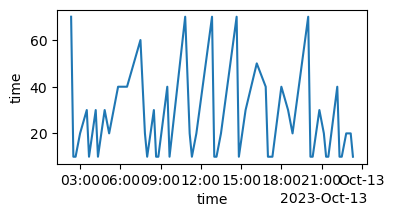

In [151]:
(1e-9/60 *dsv8.CMI.time.diff('time')).plot(size=2, aspect=2); # minutes between images 

Original times: 53 -> Regular times: 48
Match ds_sat? True


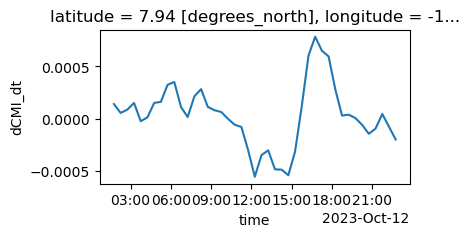

In [148]:
# 1. Interpolate all channels to match ds_sat's time coordinate for derivative operation
# This creates uniform 30-min spacing, eliminating irregular gaps.
dsv8_reg = dsv8['CMI'].interp_like(ds_sat.time, method='linear')
dsv9_reg = dsv9['CMI'].interp_like(ds_sat.time, method='linear') 
dsv10_reg = dsv10['CMI'].interp_like(ds_sat.time, method='linear')

# 2. Calculate derivatives on the now-perfectly-regular grid
dsv8_reg['dCMI_dt'] = dsv8_reg.differentiate('time', datetime_unit='s')
dsv9_reg['dCMI_dt'] = dsv9_reg.differentiate('time', datetime_unit='s')
dsv10_reg['dCMI_dt'] = dsv10_reg.differentiate('time', datetime_unit='s')

# Quick check: Time coordinates should now be identical to ds_sat
print(f"Original times: {len(dsv8.time)} -> Regular times: {len(dsv8_reg.time)}")
print(f"Match ds_sat? {dsv8_reg.time.equals(ds_sat.time)}")

# Plot test
dsv8_reg['dCMI_dt'][:, 50, 50].plot(label='Regular Derivative', size=2, aspect=2);

In [65]:
# Satellite IR Tb (CMI) animation with cross section lines on it 

# SW to NE cross section: indicate this central transect and its averaging band on the animation 
lat_ne, lon_ne = -11, -88 
lat_sw, lon_sw = -23, -97 
XSEC_WIDTH = 500 # km 

# compute offset in degrees for the band edges
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length_deg = np.sqrt(dlat**2 + dlon**2)
perp_lat =  (dlon / length_deg) * (XSEC_WIDTH / 111.32)
perp_lon = -(dlat / length_deg) * (XSEC_WIDTH / 111.32)

# CMI 
CMI = ds_sat.CMI.sel(time=slice('2023-10-12-T12','2023-10-12-T23'), latitude=slice(-11, -24), longitude=slice(-102,-88))

# make animation data list  
data = [(CMI.isel(time=t)) for t in range(len(CMI.time))]


# Plot title 
titlestring = "GOES-16 IR CMI, "

fig, ax = plt.subplots()
sm = plt.cm.ScalarMappable(cmap='Greys', norm=mcolors.Normalize(vmin=275, vmax=300))
plt.colorbar(sm, ax=ax, label='K')
ax.set_aspect('equal')

ani = animation.FuncAnimation(fig, lambda f: (ax.clear(),
                                              data[f].plot(ax=ax, add_colorbar=False, vmin=275, vmax=300, cmap='Greys'),
                                              ax.plot([lon_sw, lon_ne], [lat_sw, lat_ne], 'w-'),
                                              ax.plot([lon_sw-perp_lon, lon_ne-perp_lon], [lat_sw-perp_lat, lat_ne-perp_lat], 'r--'),
                                              ax.plot([lon_sw+perp_lon, lon_ne+perp_lon], [lat_sw+perp_lat, lat_ne+perp_lat], 'r--'),
                                              ax.set_title(titlestring + ax.get_title())),
                                              frames=len(data), interval=100)

ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/CMIanimation.gif', writer='pillow')
ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/CMIanimation.mp4')

display(HTML(ani.to_jshtml()))
plt.close()

In [154]:
# Satellite WV8 d/dt of Tb (CMI) animation with cross section lines on it 

# SW to NE cross section: indicate this central transect and its averaging band on the animation 
lat_ne, lon_ne = -11, -88 
lat_sw, lon_sw = -23, -97 
XSEC_WIDTH = 500 # km 

# compute offset in degrees for the band edges
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length_deg = np.sqrt(dlat**2 + dlon**2)
perp_lat =  (dlon / length_deg) * (XSEC_WIDTH / 111.32)
perp_lon = -(dlat / length_deg) * (XSEC_WIDTH / 111.32)

# dCMIdt in K/h
dCMIdt8 = 3600.*dsv8_reg.dCMI_dt.sel(time=slice('2023-10-12-T12','2023-10-12-T23'), 
                                 latitude=slice(-11, -24), longitude=slice(-102,-88))
vmin,vmax = -5,5
# make animation data list  
data = [(dCMIdt8.isel(time=t)) for t in range(len(dCMIdt8.time))]


# Plot title 
titlestring = "GOES-16 IR dCMIdt8, "

fig, ax = plt.subplots()
sm = plt.cm.ScalarMappable(cmap='RdBu_r')  #, norm=mcolors.Normalize(vmin=-1, vmax=1))
plt.colorbar(sm, ax=ax, label='K/h')
ax.set_aspect('equal')

ani = animation.FuncAnimation(fig, lambda f: (ax.clear(),
                                              data[f].plot(ax=ax, add_colorbar=False, vmin=vmin, vmax=vmax, cmap='RdBu_r'),
                                              ax.plot([lon_sw, lon_ne], [lat_sw, lat_ne], 'w-'),
                                              ax.plot([lon_sw-perp_lon, lon_ne-perp_lon], [lat_sw-perp_lat, lat_ne-perp_lat], 'r--'),
                                              ax.plot([lon_sw+perp_lon, lon_ne+perp_lon], [lat_sw+perp_lat, lat_ne+perp_lat], 'r--'),
                                              ax.set_title(titlestring + ax.get_title())),
                                              frames=len(data), interval=100)

ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/dCMIdt8animation.gif', writer='pillow')
ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/dCMIdt8animation.mp4')

display(HTML(ani.to_jshtml()))
plt.close()

In [155]:
# Satellite WV9 d/dt of Tb (CMI) animation with cross section lines on it 

# SW to NE cross section: indicate this central transect and its averaging band on the animation 
lat_ne, lon_ne = -11, -88 
lat_sw, lon_sw = -23, -97 
XSEC_WIDTH = 500 # km 

# compute offset in degrees for the band edges
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length_deg = np.sqrt(dlat**2 + dlon**2)
perp_lat =  (dlon / length_deg) * (XSEC_WIDTH / 111.32)
perp_lon = -(dlat / length_deg) * (XSEC_WIDTH / 111.32)

# dCMIdt in K/h
dCMIdt9 = 3600.*dsv9_reg.dCMI_dt.sel(time=slice('2023-10-12-T12','2023-10-12-T23'), 
                                 latitude=slice(-11, -24), longitude=slice(-102,-88))
vmin,vmax = -5,5
# make animation data list  
data = [(dCMIdt9.isel(time=t)) for t in range(len(dCMIdt9.time))]


# Plot title 
titlestring = "GOES-16 IR dCMIdt9, "

fig, ax = plt.subplots()
sm = plt.cm.ScalarMappable(cmap='RdBu_r')  #, norm=mcolors.Normalize(vmin=-1, vmax=1))
plt.colorbar(sm, ax=ax, label='K/h')
ax.set_aspect('equal')

ani = animation.FuncAnimation(fig, lambda f: (ax.clear(),
                                              data[f].plot(ax=ax, add_colorbar=False, vmin=vmin, vmax=vmax, cmap='RdBu_r'),
                                              ax.plot([lon_sw, lon_ne], [lat_sw, lat_ne], 'w-'),
                                              ax.plot([lon_sw-perp_lon, lon_ne-perp_lon], [lat_sw-perp_lat, lat_ne-perp_lat], 'r--'),
                                              ax.plot([lon_sw+perp_lon, lon_ne+perp_lon], [lat_sw+perp_lat, lat_ne+perp_lat], 'r--'),
                                              ax.set_title(titlestring + ax.get_title())),
                                              frames=len(data), interval=100)

ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/dCMIdt9animation.gif', writer='pillow')
ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/dCMIdt9animation.mp4')

display(HTML(ani.to_jshtml()))
plt.close()

In [156]:
# Satellite WV10 d/dt of Tb (CMI) animation with cross section lines on it 

# SW to NE cross section: indicate this central transect and its averaging band on the animation 
lat_ne, lon_ne = -11, -88 
lat_sw, lon_sw = -23, -97 
XSEC_WIDTH = 500 # km 

# compute offset in degrees for the band edges
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length_deg = np.sqrt(dlat**2 + dlon**2)
perp_lat =  (dlon / length_deg) * (XSEC_WIDTH / 111.32)
perp_lon = -(dlat / length_deg) * (XSEC_WIDTH / 111.32)

# dCMIdt in K/h
dCMIdt10 = 3600.*dsv10_reg.dCMI_dt.sel(time=slice('2023-10-12-T12','2023-10-12-T23'), 
                                   latitude=slice(-11, -24), longitude=slice(-102,-88))
vmin,vmax = -5,5
# make animation data list  
data = [(dCMIdt10.isel(time=t)) for t in range(len(dCMIdt9.time))]


# Plot title 
titlestring = "GOES-16 IR dCMIdt10, "

fig, ax = plt.subplots()
sm = plt.cm.ScalarMappable(cmap='RdBu_r')  #, norm=mcolors.Normalize(vmin=-1, vmax=1))
plt.colorbar(sm, ax=ax, label='K/h')
ax.set_aspect('equal')

ani = animation.FuncAnimation(fig, lambda f: (ax.clear(),
                                              data[f].plot(ax=ax, add_colorbar=False, vmin=vmin, vmax=vmax, cmap='RdBu_r'),
                                              ax.plot([lon_sw, lon_ne], [lat_sw, lat_ne], 'w-'),
                                              ax.plot([lon_sw-perp_lon, lon_ne-perp_lon], [lat_sw-perp_lat, lat_ne-perp_lat], 'r--'),
                                              ax.plot([lon_sw+perp_lon, lon_ne+perp_lon], [lat_sw+perp_lat, lat_ne+perp_lat], 'r--'),
                                              ax.set_title(titlestring + ax.get_title())),
                                              frames=len(data), interval=100)

ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/dCMIdt10animation.gif', writer='pillow')
ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/dCMIdt10animation.mp4')

display(HTML(ani.to_jshtml()))
plt.close()

In [69]:
# Overlay PIVdiv on CMI 

# smooth div in time, lat, lon, lightly 
xytsmoodiv = dsp.divergence.rolling(time=3, latitude=2, longitude=2, center=True).mean()
data = [xytsmoodiv.isel(time=t) for t in range(len(xytsmoodiv.time)-3)]

# Data sets for overlay: 
data = [CMI.isel(time=t) for t in range(CMI.sizes['time'])]
div  = [xytsmoodiv.sel(time=t, method='nearest').sel(latitude=slice(-12,-23), longitude=slice(-102,-88)) 
        for t in CMI.time.values]

# Make div a da with same-time-lat-lon shape as CMI 
div_da = xr.concat(div, dim=CMI.time)
div_da = div_da.interp(latitude=CMI.latitude, longitude=CMI.longitude)


titlestring = "sat. CMI + sat. PIV div, "

fig, ax = plt.subplots()
ax.set_aspect('equal')
sm = plt.cm.ScalarMappable(cmap='Greys', norm=mcolors.Normalize(vmin=275, vmax=300))
plt.colorbar(sm, ax=ax, label='K')


ani = animation.FuncAnimation(fig, lambda f: (ax.clear(),
                                              data[f].plot(ax=ax, add_colorbar=False, vmin=275, vmax=300, cmap='Greys'),
                                              div[f].plot.contour(ax=ax, levels=np.linspace(-0.2e-4, 0.2e-4, 6)),
                                              ax.plot([lon_sw, lon_ne], [lat_sw, lat_ne], 'w-'),
                                              ax.plot([lon_sw-perp_lon, lon_ne-perp_lon], [lat_sw-perp_lat, lat_ne-perp_lat], 'r--'),
                                              ax.plot([lon_sw+perp_lon, lon_ne+perp_lon], [lat_sw+perp_lat, lat_ne+perp_lat], 'r--'),                                              ax.set_title(titlestring + ax.get_title())),
                                              frames=len(data), interval=300)

ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/CMI_divcontours_animation.gif', writer='pillow')
ani.save('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/CMI_divcontours_animation.mp4')

display(HTML(ani.to_jshtml()))
plt.close()

------------
# Build a transect for clearest possible lon-time plot 

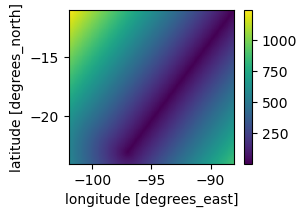

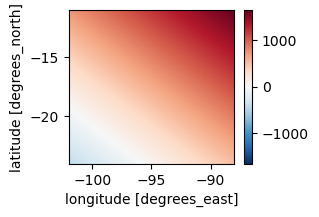

In [164]:
# Mean transect construction: step 1, compute array of distances from diagonal line 

from scipy.spatial.distance import cdist

# --- define transect line as array of (lat,lon) points -----------------
n = 200
lat_line = np.linspace(lat_sw, lat_ne, n)
lon_line = np.linspace(lon_sw, lon_ne, n)
line_pts = np.column_stack([lat_line, lon_line])

# --- distance from every grid point to nearest point on the line -------
LAT2D, LON2D = np.meshgrid(lcc.latitude, lcc.longitude, indexing='ij')
grid_pts = np.column_stack([LAT2D.ravel(), LON2D.ravel()])

# minimum distance to any point on the line, in degrees (approx)
dist_to_line = cdist(grid_pts, line_pts).min(axis=1).reshape(LAT2D.shape)
dist_km = dist_to_line * 111.32   # rough degrees→km

# LCC dist_da
dist_da = xr.DataArray(dist_km, dims=['latitude','longitude'],
                        coords={'latitude': lcc.latitude, 'longitude': lcc.longitude})

dist_da.plot(size=2);

# Step 3: TO bin by along-line distince index, we need a 2D array of that distance

# unit vector along transect
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length = np.sqrt(dlat**2 + dlon**2)
ulat, ulon = dlat/length, dlon/length

# signed along-transect distance from SW end (degrees)
along = ((LAT2D - lat_sw)*ulat + (LON2D - lon_sw)*ulon) * 111.32  # km

# LCC along_da
along_da = xr.DataArray(along, dims=['latitude','longitude'],
                         coords={'latitude': lcc.latitude, 'longitude': lcc.longitude})
# DIV along_da2: not so easy, "along" is also specific to lcc data grid. Sigh. 
# along_da2 = xr.DataArray(along, dims=['latitude','longitude'],
#                          coords={'latitude': div_da.latitude, 'longitude': div_da.longitude})

along_da.plot(size=2);

# Hovmuller of PIVdiv on ERA5 lcc 

In [165]:
# bin-average ERA5 lcc and div by distance ALONG, after masking for distance ACROSS 

# Mask lcc for the band 
lccband = lcc.where(dist_da < XSEC_WIDTH)   # mask for all points within 100km of line

divband = div_da.where(dist_da < XSEC_WIDTH)   # mask for all points within 100km of line

CMIband = CMI.where(dist_da < XSEC_WIDTH)   # mask for all points within 100km of line

dCMIdt8band = dCMIdt8.where(dist_da < XSEC_WIDTH)
dCMIdt9band = dCMIdt9.where(dist_da < XSEC_WIDTH)
dCMIdt10band = dCMIdt10.where(dist_da < XSEC_WIDTH)


# 80 bins for averaging the lcc field (masked in a belt), bins are by distance along the transect
bins = np.linspace(0, float(along_da.where(dist_da < XSEC_WIDTH).max()), 80)
labels = 0.5*(bins[:-1] + bins[1:])

groupedlcc = (lccband.assign_coords(along=along_da)
               .groupby_bins('along', bins=bins, labels=labels)
               .mean())
groupeddiv = (divband.assign_coords(along=along_da)
               .groupby_bins('along', bins=bins, labels=labels)
               .mean())
groupedCMI = (CMIband.assign_coords(along=along_da)
               .groupby_bins('along', bins=bins, labels=labels)
               .mean())
groupedddt8 = (dCMIdt8band.assign_coords(along=along_da)
               .groupby_bins('along', bins=bins, labels=labels).mean())
groupedddt9 = (dCMIdt9band.assign_coords(along=along_da)
               .groupby_bins('along', bins=bins, labels=labels).mean())
groupedddt10 = (dCMIdt10band.assign_coords(along=along_da)
               .groupby_bins('along', bins=bins, labels=labels).mean())

lon_bins = np.linspace(lon_sw, lon_ne, len(bins)-1)

grouped = xr.Dataset({'lcc': groupedlcc, 'div': groupeddiv})
grouped['along_bins'] = lon_bins
grouped['along_bins'].attrs['long_name'] = 'Longitude'

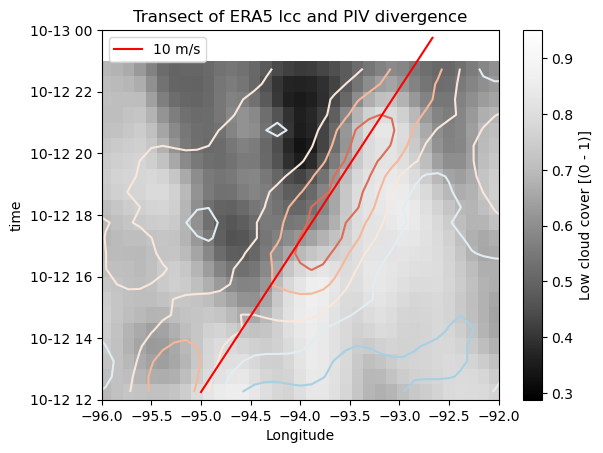

In [166]:
# Make the plot: div on lcc 
grouped.lcc.plot(cmap='Greys_r');
grouped.div.plot.contour(levels=np.linspace(-0.2e-4, 0.2e-4, 10));

plt.xlim([-96, -92]);

# Annotation line for 14 m/s 
c_line = 10 # m/s

# fraction of motion that projects onto longitude axis
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length_deg = np.sqrt(dlat**2 + dlon**2)
lon_fraction = dlon / length_deg   # how much of along-transect is in lon direction

# 14 m/s line 
cos_lat = np.cos(np.radians(0.5*(lat_sw + lat_ne)))
speed_deglon_per_sec = c_line / (111320 * cos_lat) * lon_fraction

# draw the line anchored at a reference point (x0_ref, t0_ref)
t0_ref = grouped.time.values[0]
t_secs = (grouped.time.values - t0_ref) / np.timedelta64(1, 's')
lon_ref = -95   # adjust anchor longitude

ax = plt.gca()
ax.plot(lon_ref + t_secs * speed_deglon_per_sec, grouped.time.values, 'r-', label=str(c_line)+' m/s')
ax.set_title('Transect of ERA5 lcc and PIV divergence')
ax.legend();

plt.savefig('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/ERA5lcc_divcontours_Hovmuller.png', 
            dpi=150, bbox_inches='tight')


# Hovmuller with CMI as the background 

rebuilds "grouped", run both cells 

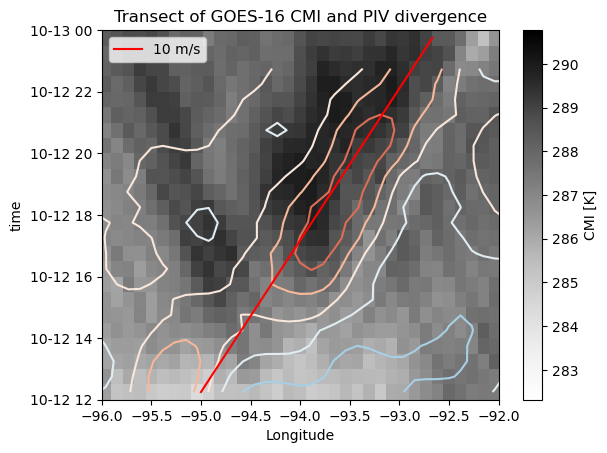

In [167]:
# Bin-average CMI by distance ALONG, after masking for distance ACROSS 

# # Mask CMI for the band 
# CMIband = CMI.where(dist_da < XSEC_WIDTH)   # mask for all points within 100km of line

# divband = div_da.where(dist_da < XSEC_WIDTH)   # mask for all points within 100km of line


# # 80 bins for averaging the CMI field (masked in a belt), bins are by distance along the transect
# bins = np.linspace(0, float(along_da.where(dist_da < XSEC_WIDTH).max()), 80)
# labels = 0.5*(bins[:-1] + bins[1:])

# groupedCMI = (CMIband.assign_coords(along=along_da)
#                .groupby_bins('along', bins=bins, labels=labels)
#                .mean())
# groupeddiv = (divband.assign_coords(along=along_da)
#                .groupby_bins('along', bins=bins, labels=labels)
#                .mean())

lon_bins = np.linspace(lon_sw, lon_ne, len(bins)-1)

grouped = xr.Dataset({'CMI': groupedCMI, 'div': groupeddiv})
grouped['along_bins'] = lon_bins
grouped['along_bins'].attrs['long_name'] = 'Longitude'

# Make the plot: div on CMI 

grouped.CMI.plot(cmap='Greys');
grouped.div.plot.contour(levels=np.linspace(-0.2e-4, 0.2e-4, 10));

plt.xlim([-96, -92]);

# Annotation line for 14 m/s 
c_line = 10 # m/s

# fraction of motion that projects onto longitude axis
dlat, dlon = lat_ne - lat_sw, lon_ne - lon_sw
length_deg = np.sqrt(dlat**2 + dlon**2)
lon_fraction = dlon / length_deg   # how much of along-transect is in lon direction

# 14 m/s line 
cos_lat = np.cos(np.radians(0.5*(lat_sw + lat_ne)))
speed_deglon_per_sec = c_line / (111320 * cos_lat) * lon_fraction

# draw the line anchored at a reference point (x0_ref, t0_ref)
t0_ref = grouped.time.values[0]
t_secs = (grouped.time.values - t0_ref) / np.timedelta64(1, 's')
lon_ref = -95   # adjust anchor longitude

ax = plt.gca()
ax.plot(lon_ref + t_secs * speed_deglon_per_sec, grouped.time.values, 'r-', label=str(c_line)+' m/s')
ax.set_title('Transect of GOES-16 CMI and PIV divergence')
ax.legend();

plt.savefig('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/satCMI_divcontours_Hovmuller.png', 
            dpi=150, bbox_inches='tight')


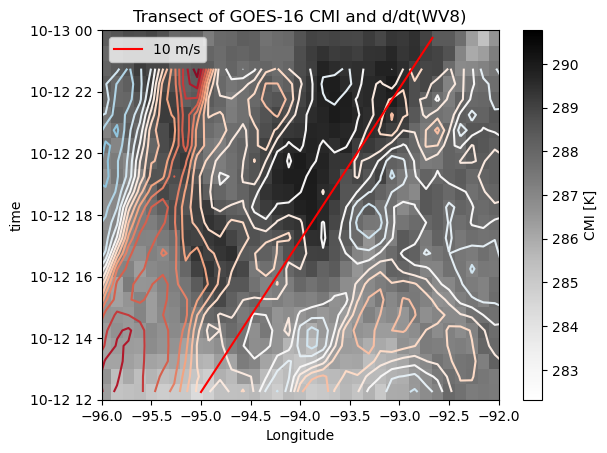

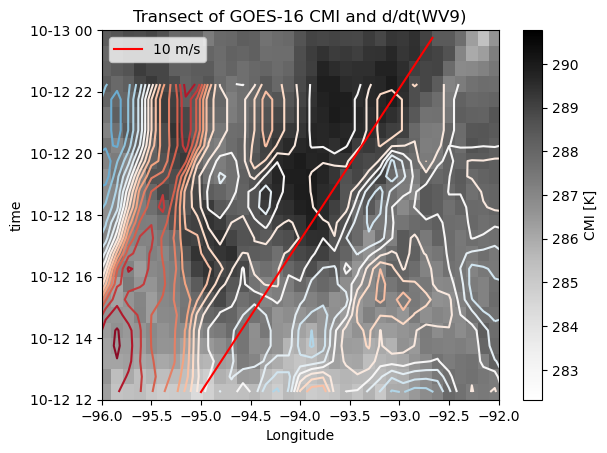

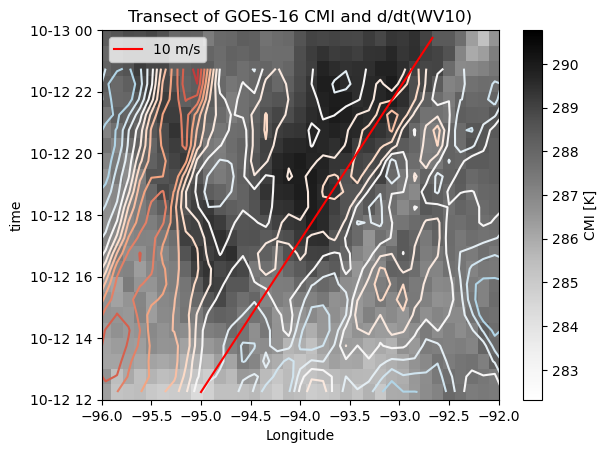

In [176]:
# Hovmuller of d/dt(WV) over CMI by distance ALONG, after masking for distance ACROSS 

# 80 bins for averaging the CMI field (masked in a belt), bins are by distance along the transect
bins = np.linspace(0, float(along_da.where(dist_da < XSEC_WIDTH).max()), 80)
labels = 0.5*(bins[:-1] + bins[1:])

grouped = xr.Dataset({'CMI': groupedCMI, 'div': groupeddiv, 'ddt8': groupedddt8, 'ddt9': groupedddt9, 'ddt10': groupedddt10})
grouped['along_bins'] = lon_bins
grouped['along_bins'].attrs['long_name'] = 'Longitude'


# Make the plot: ddt8 on CMI 
plt.figure()
grouped.CMI.plot(cmap='Greys');
grouped.ddt8.plot.contour(levels=np.linspace(-1, 1, 21));
plt.xlim([-96, -92]);
ax = plt.gca()
ax.plot(lon_ref + t_secs * speed_deglon_per_sec, grouped.time.values, 'r-', label=str(c_line)+' m/s')
ax.set_title('Transect of GOES-16 CMI and d/dt(WV8)')
ax.legend();

plt.savefig('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/'+ \
            'satCMI_ddt8contours_Hovmuller.png', 
            dpi=150, bbox_inches='tight')


# Make the plot: ddt9 on CMI 
plt.figure()

grouped.CMI.plot(cmap='Greys');
grouped.ddt9.plot.contour(levels=np.linspace(-1, 1, 21));
plt.xlim([-96, -92]);
ax = plt.gca()
ax.plot(lon_ref + t_secs * speed_deglon_per_sec, grouped.time.values, 'r-', label=str(c_line)+' m/s')
ax.set_title('Transect of GOES-16 CMI and d/dt(WV9)')
ax.legend();

plt.savefig('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/'+ \
            'satCMI_ddt9contours_Hovmuller.png', 
            dpi=150, bbox_inches='tight')


# Make the plot: ddt10 on CMI 
plt.figure()

grouped.CMI.plot(cmap='Greys');
grouped.ddt10.plot.contour(levels=np.linspace(-1, 1, 21));
plt.xlim([-96, -92]);
ax = plt.gca()
ax.plot(lon_ref + t_secs * speed_deglon_per_sec, grouped.time.values, 'r-', label=str(c_line)+' m/s')
ax.set_title('Transect of GOES-16 CMI and d/dt(WV10)')
ax.legend();

plt.savefig('/Users/bmapes/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/2023-10-12_first_attempts/'+ \
            'satCMI_ddt10contours_Hovmuller.png', 
            dpi=150, bbox_inches='tight')
